# **Playing Card** Datasets exploration
Initial dataset exploration

In [1]:
DATASET_NAMES = ["pcd_src_kaggle", "pcd_src_robo_plain"]

In [2]:
# ===== DIR_ROOT, DIR_DATASETS, DIR_DATASETS_ORIG

from pathlib import Path
DIR_ROOT = Path.cwd().parent
DIR_DATASETS = DIR_ROOT / "datasets"
DIR_DATASETS_ORIG = DIR_DATASETS / "original"

## 0. Download

### Kaggle dataset
1. Go to [this link](https://www.kaggle.com/datasets/andy8744/playing-cards-object-detection-dataset) on Kaggle (https://www.kaggle.com/datasets/andy8744/playing-cards-object-detection-dataset)
2. In the top-right corner press on `Download`
3. Select `Download dataset as zip (706 MB)`
4. Move the downloaded file (usually called `archive.zip`) into the `/datasets/original` folder

### Roboflow dataset
1. Go to [this link](https://universe.roboflow.com/augmented-startups/playing-cards-ow27d/dataset/3) on Roboflow (https://universe.roboflow.com/augmented-startups/playing-cards-ow27d/dataset/3)
2. Select `Download Dataset`
3. In the opened pop-up, select once again `Download Dataset`, the press `Continue`
4. Set `Image and Annotation Format` to `YOLOv11`
5. Under `Download Options` select `Download zip to computer`
6. Press `Continue`
7. Move the downloaded file (usually called `Playing Cards.v3-original_raw-images.yolov11.zip`) into the `/datasets/original` folder

## 1. Extraction

In [3]:
# Set this to True is dataset are downloaded as zip files and not extracted yet
EXTRACT_DATASETS = False

# List of zip files to extract, structure:
#    zip file name: folder name
DATASETS_TO_EXTRACT = [
    ("archive.zip", DATASET_NAMES[0]),
    ("Playing Cards.v3-original_raw-images.yolov11.zip", DATASET_NAMES[1]),
]

In [4]:
# ===== Datasets extraction

import zipfile

if EXTRACT_DATASETS:
    for zip_name, ds_dir_name in DATASETS_TO_EXTRACT:
    
        zip_file = DIR_DATASETS_ORIG / zip_name
        folder_path = DIR_DATASETS / ds_dir_name
    
        # Create dir if not existing
        folder_path.mkdir(parents=True, exist_ok=True)
    
        # Extract zip file into specified folder
        with zipfile.ZipFile(zip_file, 'r') as z:
            z.extractall(folder_path)

In [5]:
# List of absolute path to the datasets to merge
DATASETS = [DIR_DATASETS / ds_name for ds_name in DATASET_NAMES]

# Error if they don't exists
missing = [d for d in DATASETS if not d.exists()]

if missing:
    raise FileNotFoundError(
        "\nDatasets not existing:\n" +
        "\n".join(str(m) for m in missing)
    )

## 2. Utility functions

### 2.A Directory structure exploration

#### 2.A.1 Print tree function

In [6]:
from collections import defaultdict

def extract_dir_tree(dataset):
    tree = {}
    
    root_counts = defaultdict(int)
    for f in dataset.iterdir():
        if f.is_file():
            ext = f.suffix.lower() if f.suffix else "no_ext"
            root_counts[ext] += 1

    tree["counts"] = dict(root_counts)

    for dirpath in sorted(p for p in dataset.rglob("*") if p.is_dir()):
        files = [f for f in dirpath.iterdir() if f.is_file()]
    
        counts = defaultdict(int)
        for f in files:
            ext = f.suffix.lower() if f.suffix else "no_ext"
            counts[ext] += 1
    
        node = tree
        for part in dirpath.relative_to(dataset).parts:
            node = node.setdefault(part, {})
    
        node["counts"] = dict(counts)
    
    return {dataset.name: tree}

In [7]:
def print_tree_iter(node, prefix=""):
    items = [(k, v) for k, v in node.items() if k != "counts"]

    for i, (name, child) in enumerate(items):
        last = i == len(items) - 1
        branch = "└── " if last else "├── "

        print(f"{prefix}{branch}{name}/")

        counts = child.get("counts", {})
        for ext, n in sorted(counts.items()):
            ext_prefix = prefix + ("    " if last else "│   ")
            print(f"{ext_prefix}├── *{ext} [{n}]")

        print_tree_iter(
            child,
            prefix + ("    " if last else "│   ")
        )

In [8]:
def print_tree(dataset_root: Path):
    
    # Extract structure
    ds_tree = extract_dir_tree(dataset_root)
    
    # Print structure
    print_tree_iter(ds_tree)

#### 2.A.2 Directory structure results

The dataset have the following structure (all datasets used):
```text
dataset/
│
├── test/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
├── train/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
├── val/
│   ├── images/
|   │   └── *.jpg
│   └── labels/
|       └── *.txt
│
└── data.yaml
```

### 2.B Information maps construction

Two functions `construct_image_map` and `construct_category_map` to collect all information from the dataset

#### 2.B.1 Image Map construction

Construct an information map of all the images in the given dataset.

- Scans the `train`, `valid`, and `test` splits,
- Matches every label file with its corresponding image (to check that every pair exists)
- Process all found images:
- Retrieve the image dimensions, parse all YOLO annotations. For each image:
  - Store the image dimensions
  - Store number of bounding boxes
  - Store the set of categories present in the image
  - Store information about each bounding box in the image:
    - Store the original normalized bounding box coordinates
    - Store the bounding box pixel equivalents
    - Store corner information
    - Store bounding box area

The map has the following structure:

```python
IMAGE_MAP = {
    "<image_stem>": {
        "split": [ 'train' | 'valid' | 'test' ],
        "dimension": (width, height),
        "bb_count": int,
        "categories": {cat_id, ...},
        "bb_list": [
            {
                "category": int,

                # Normalized coordinates
                "center_norm": (x_center, y_center),
                "size_norm": (width, height),

                # Pixel coordinates
                "center_px": (x_center_px, y_center_px),
                "size_px": (width_px, height_px),

                # Pixel corner coordinates
                "top_left": (x1, y1),
                "bottom_right": (x2, y2),

                # Bounding box area
                "area_px": float,
                "area_norm": float
            },
            ...
        ]
    },
    ...
}
```

In [9]:
from PIL import Image

FOLDERS = ["train", "valid", "test"]

def construct_image_map(dataset: Path):

    IMAGE_MAP = {}

    # Loop over all three folder
    for folder in FOLDERS:

        # Loop over all label files
        for file in Path(dataset / folder / 'labels').iterdir():
            if file.is_file() and file.suffix.lower() == ".txt":
                
                # Find the corresponding image
                image_path = None
                for ext in (".jpg", ".jpeg", ".png", ".bmp", ".webp"):
                    candidate = file.parent.parent / "images" / f"{file.stem}{ext}"
                    if candidate.exists():
                        image_path = candidate
                        break

                if image_path is None:
                    print(f"WARNING: image not found for {file.name}")
                    continue

                with Image.open(image_path) as img:
                    img_w, img_h = img.size
                    
                with open(file, "r", encoding="utf-8") as f:
                    
                    # Create new image entry if not exists
                    if file.stem not in IMAGE_MAP:
                        IMAGE_MAP[file.stem] = {

                            # List of bounding boxes
                            "bb_list": [],

                            # Image dimensions
                            "dimension": (img_w, img_h),

                            "split": folder,

                            # Redundant information
                            "bb_count": 0,
                            "categories": set()
                        }

                    else:
                        print(f"WARNING: duplicate stem detected: {file.stem}")

                    # Loop over each bounding box
                    for line in f:

                        # Get original information
                        cat_idx, xc, yc, w, h = map(float, line.split())
                        cat_idx = int(cat_idx)

                        # Convert normalized coordinates into pixels
                        xc_px = xc * img_w
                        yc_px = yc * img_h
                        w_px = w * img_w
                        h_px = h * img_h

                        # Corners coordinates
                        x1 = xc_px - w_px / 2
                        y1 = yc_px - h_px / 2
                        x2 = xc_px + w_px / 2
                        y2 = yc_px + h_px / 2

                        # Area in pixel squared
                        area = w_px * h_px
                        
                        # Area normalized over image area
                        rel_area = w * h  

                        # Store bounding box information
                        IMAGE_MAP[file.stem]["bb_list"].append({
                            "category": cat_idx,

                            # Normalized coordinates
                            "center_norm": (xc, yc),
                            "size_norm": (w, h),

                            # Pixel coordinates
                            "center_px": (xc_px, yc_px),
                            "size_px": (w_px, h_px),

                            # Corner coordinates
                            "top_left": (x1, y1),
                            "bottom_right": (x2, y2),

                            # Area
                            "area_px": area,
                            "area_norm": rel_area
                        })

                        # Update redundant information
                        IMAGE_MAP[file.stem]["bb_count"] += 1
                        IMAGE_MAP[file.stem]["categories"].add(cat_idx)

    return IMAGE_MAP

#### 2.B.2 Category map construction

Construct an information map of all the categories in the given dataset.

- Read category names from `data.yaml`
- Scan the previously generated `IMAGE_MAP` to combine all category related information. For every category store:
  - Category name
  - Category rank and suit (extracted frrom the name)
  - List of bounding boxes belonging to that class
  - Set of images in which the category appears,
  - Total number of bounding boxes

Map structure:

```python
CATEGORY_MAP = {
    <category_id>: {
        "name": str,
        "rank": str,
        "suit": str,

        # Images containing this category
        "images": {image_name, ...},

        # Total number of bounding boxes
        "bb_count": int,

        # References to all bounding boxes of this category
        "bb_list": [
            bb1,
            bb2,
            ...
        ]
    },
    ...
}
```

In [10]:
import yaml

def construct_category_map(dataset: Path, IMAGE_MAP):
    CATEGORY_MAP = {}

    # 1) get categories info from yaml
    with open(dataset / "data.yaml", "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    for cat_idx, cat_name in enumerate(data["names"]):

        if cat_idx not in CATEGORY_MAP:
            CATEGORY_MAP[cat_idx] = {
                "name": cat_name,
                "suit": cat_name[-1:], # last chars
                "rank": cat_name[:-1], # other chars
                "images": set(),
                "bb_count": 0,
                "bb_list": [],
            }

    # 2) fetch information from image map
    for image_name, image_info in IMAGE_MAP.items():
        for bb in image_info["bb_list"]:
            cat = bb["category"]
    
            if cat not in CATEGORY_MAP:
                print("WARNING: category not recognized")
                continue
    
            CATEGORY_MAP[cat]["bb_count"] += 1
            CATEGORY_MAP[cat]["images"].add(image_name)
            CATEGORY_MAP[cat]["bb_list"].append(bb)
    
    return CATEGORY_MAP

### 2.C Information print

#### 2.C.0 General information

In [11]:
def print_general_info(IMAGE_MAP, CATEGORY_MAP):

    print("\n--- GENERAL DATASET INFO ---")
    print(f"Total images: {len(IMAGE_MAP)}")
    
    images_with_boxes = sum(1 for img in IMAGE_MAP.values() if img["bb_count"] > 0)
    print(f"   Images with at least 1 bbox: {images_with_boxes}")
    
    print(f"Total categories: {len(CATEGORY_MAP)}")
    
    total_bboxes = sum(img["bb_count"] for img in IMAGE_MAP.values())
    print(f"Total bounding boxes: {total_bboxes}")

#### 2.C.1 Images information

In [12]:
import numpy as np

def print_images_stats(
    IMAGE_MAP,
    top_by_bb_count=5,
    bottom_by_bb_count=5,
    top_by_cat_count=5,
    bottom_by_cat_count=5
):

    bb_counts = np.array([img["bb_count"] for img in IMAGE_MAP.values()])
    cat_counts = np.array([len(img["categories"]) for img in IMAGE_MAP.values()])

    print("\n--- IMAGE STATISTICS ---")
    print(f"Mean bboxes per image: {bb_counts.mean():.2f} (stddev: {bb_counts.std():.2f})")
    print(f"Min/Max bboxes per image: {bb_counts.min()} / {bb_counts.max()}")

    print(f"Mean categories per image: {cat_counts.mean():.2f} (stddev: {cat_counts.std():.2f})")
    print(f"Min/Max categories per image: {cat_counts.min()} / {cat_counts.max()}")


    sorted_by_bb = sorted(IMAGE_MAP.items(), key=lambda x: x[1]["bb_count"])
    sorted_by_cat = sorted(IMAGE_MAP.items(), key=lambda x: len(x[1]["categories"]))
    
    print("\n--- TOP IMAGES BY BBOX COUNT ---")
    for name, info in sorted_by_bb[-top_by_bb_count:][::-1]:
        print(f"> {name}: {info['bb_count']}")

    print("\n--- BOTTOM IMAGES BY BBOX COUNT ---")
    for name, info in sorted_by_bb[:bottom_by_bb_count]:
        print(f"> {name}: {info['bb_count']}")

    print("\n--- TOP IMAGES BY CATEGORY COUNT ---")
    for name, info in sorted_by_cat[-top_by_cat_count:][::-1]:
        print(f"> {name}: {len(info['categories'])}")

    print("\n--- BOTTOM IMAGES BY CATEGORY COUNT ---")
    for name, info in sorted_by_cat[:bottom_by_cat_count]:
        print(f"> {name}: {len(info['categories'])}")

#### 2.C.2 Categories information

In [13]:
def print_categories_stats(
    CATEGORY_MAP,
    top_by_bb_count=5,
    bottom_by_bb_count=5,
    top_by_image_count=5,
    bottom_by_image_count=5
):

    bb_counts = np.array([cat["bb_count"] for cat in CATEGORY_MAP.values()])
    img_counts = np.array([len(cat["images"]) for cat in CATEGORY_MAP.values()])

    sorted_by_bb = sorted(CATEGORY_MAP.items(), key=lambda x: x[1]["bb_count"])
    sorted_by_img = sorted(CATEGORY_MAP.items(), key=lambda x: len(x[1]["images"]))

    print("\n--- TOP CATEGORIES BY BBOX COUNT ---")
    for cat_id, info in sorted_by_bb[-top_by_bb_count:][::-1]:
        print(f"> {info['name']:>3} (id={cat_id:>2}): {info['bb_count']}")

    print("\n--- BOTTOM CATEGORIES BY BBOX COUNT ---")
    for cat_id, info in sorted_by_bb[:bottom_by_bb_count]:
        print(f"> {info['name']:>3} (id={cat_id:>2}): {info['bb_count']}")

    print("\n--- TOP CATEGORIES BY IMAGE COUNT ---")
    for cat_id, info in sorted_by_img[-top_by_image_count:][::-1]:
        print(f"> {info['name']:>3} (id={cat_id:>2}): {len(info['images'])}")

    print("\n--- BOTTOM CATEGORIES BY IMAGE COUNT ---")
    for cat_id, info in sorted_by_img[:bottom_by_image_count]:
        print(f"> {info['name']:>3} (id={cat_id:>2}): {len(info['images'])}")

    print("\n--- CATEGORY STATISTICS ---")
    print(f"Mean bboxes per category: {bb_counts.mean():.2f} (stddev: {bb_counts.std():.2f})")
    print(f"Min/Max bboxes per category: {bb_counts.min()} / {bb_counts.max()}")

    print(f"Mean images per category: {img_counts.mean():.2f} (stddev: {img_counts.std():.2f})")
    print(f"Min/Max images per category: {img_counts.min()} / {img_counts.max()}")

    
    if bb_counts.min() > 0:
        print(f"Imbalance ratio (bboxes): {bb_counts.max() / bb_counts.min():.2f}")

### 2.D Plot bounding boxes geometric information

In [14]:
import matplotlib.pyplot as plt

In [15]:
def plot_center_heatmap(image_map, bins=50):
    """ Plot of bboxes center coordinateds (noormalized) """
    plt.clf()

    xs = []
    ys = []

    for img in image_map.values():
        for bb in img["bb_list"]:
            x, y = bb["center_norm"]
            xs.append(x)
            ys.append(y)

    plt.figure(figsize=(6, 5))
    plt.hist2d(xs, ys, bins=bins, range=[[0, 1], [0, 1]])
    plt.colorbar(label="BBox count")

    plt.title("Bounding boxes center (Normalized)")
    plt.xlabel("Center X")
    plt.ylabel("Center Y")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [51]:
def plot_size_normalized(image_map):
    """ Scatter plot of width - height (normalized)"""
    plt.clf()

    widths = []
    heights = []

    for img in image_map.values():
        for bb in img["bb_list"]:
            w, h = bb["size_norm"]
            widths.append(w)
            heights.append(h)

    plt.figure(figsize=(6, 5))
    plt.scatter(widths, heights, s=8, alpha=0.4)

    plt.title("Bounding boxes size (Normalized)")
    plt.xlabel("Normalized width")
    plt.ylabel("Normalized height")
    plt.xlim(0, 0.2)
    plt.ylim(0, 0.2)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [17]:
def plot_size_pixels(image_map):
    """ Scatter plot of width - height (pixels)"""
    plt.clf()

    widths = []
    heights = []

    for img in image_map.values():
        for bb in img["bb_list"]:
            w, h = bb["size_px"]

            if w > 0 and h > 0:
                widths.append(w)
                heights.append(h)

    plt.figure(figsize=(6, 5))
    plt.scatter(widths, heights, s=8, alpha=0.4)

    plt.title("Bounding boxes size (pixels)")
    plt.xlabel("Width (px)")
    plt.ylabel("Height (px)")
    plt.grid(True, which="both")

    plt.tight_layout()
    plt.show()

### 2.E Top-card bounding box analysis

#### Definition

##### Objective and problem
In order to keep track of each **card** we would like to be able to know wheter two detection of the same class (rank+suit) belong to a same underlying physical card. With these datasets the bounding boxes are located on the **corner** of the card, over the rank and suit: this will result, for every card fully visibile, in two object detected of the same class (rank+suit)

##### Idea
Both the dimension of the bounding box and the relative position between boxes are related to the dimension of the card. Both the dimension and the distance are fixed to the pyisical card, and scale with to the card size.
Hence we could try to derive a geometric relation between two bounding boxes of the same card, and compare it to the value of the same relation on a pair of bounding boxes belonging to different cards.

***Important note***
From our datasets we do **not** have information wheter two bounding boxes of the same class in a given image belong to the same physical card. We could try to approximate this information considering that top-of-deck cards have all corners visibile, while occluded cards have only one corner visibile.

Under this approach, we treat *same-class* pairs as potential *same-card* pairs, excluding a limit case: we don't consider cases were three or more bounding boxes of the same class are recognized, as there is not way to pair some or all bbox according to their physical card

We highlight a probelm with this approach: there could be two same-class cards, both occluded: following our approach they will be considered as a same-card pair. We think that this does not influence our result too much, because there is guaranteed a top card for each image, while the number of same-class cards both covered is far lower.

##### Proposed approach
For the Same-Card Recognition metric we chose the *distance* between two bounding boxes centers over the square root of the avreage of their areas:

Given a bounding box ${bb}_i$ we indicate with:
- $(x_i, y_i)$ the normalized coordinated of its center
- $A_i$ its normalized area 


Given a pair of bounding boxs ${bb}_1$ and ${bb}_2$ we can define:
- The distance ***d*** between the centers of the bounding boxes:
$$d = \sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}$$ 
- The average of their areas ***avgA***:
$$\mathrm{avgA} = \frac{A_1 + A_2}{2}$$

We can finally define out metric ***m*** as:
$$m = \frac{d}{\sqrt{\mathrm{avgA}}}$$

The complete metric can be written as:
$$m(\mathrm{bb}_1,\mathrm{bb}_2) =
\frac{\sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}}
{\sqrt{\frac{A_1 + A_2}{2}}}$$$$

#### Utility functions

In [58]:
from collections import defaultdict
import numpy as np
import random
import matplotlib.pyplot as plt

##### Metric(s)

In [59]:
# The proposed metric
def metric_DoA(bb1, bb2):
    x1, y1 = bb1["center_norm"]
    x2, y2 = bb2["center_norm"]

    d = np.linalg.norm([x1 - x2, y1 - y2])

    A = 0.5 * (bb1["area_norm"] + bb2["area_norm"])

    return d / np.sqrt(A)

# Function to compute scores of each pair of a list 
def compute_metric(pairs, metric):
    return [metric(a, b) for a, b in pairs]

##### Build pairs of BBoxes

In [60]:
# Build two lists of pairs of bounding boxes:
# - first list is composed of pairs of bounding boxes of the same class
# - second list iscomposed of pairs of bounding boxes of different class
def build_pairs(IMAGE_MAP):

    # Positivity: same class
    pos = []
    neg = []

    # loop over all images
    for img in IMAGE_MAP.values():

        # istf of bb of the image
        bbs = img["bb_list"]

        # group by image
        by_class = defaultdict(list)
        for bb in bbs:
            by_class[bb["category"]].append(bb)

        # positive pair: only if 2 boxes per class
        for group in by_class.values():
            if len(group) == 2:
                pos.append((group[0], group[1]))

        # negatives: every possible pair with different classes
        classes = list(by_class.keys())

        # double loop -> piar of distinct classes
        for i in range(len(classes)):
            for j in range(i + 1, len(classes)):

                # for each pair (Ci, Cj) we can cross 
                # all their bounding boxes
                for bb1 in by_class[classes[i]]:
                    for bb2 in by_class[classes[j]]:
                        neg.append((bb1, bb2))

    return pos, neg


def balance_pair_lists(pos, neg, seed=42):

    # get the len of the shortes one
    n = min(len(pos), len(neg))

    # randomly subsample the shortet set
    rng = random.Random(seed)

    if len(pos) > n:
        pos = rng.sample(pos, n)
    if len(neg) > n:
        neg = rng.sample(neg, n)

    return pos, neg

##### Empirical probability curve estimation
Construct an empirical estimate of the probability that a pair of bounding boxes belongs to the same card given (conditioned) the value of the metric *M*.

Call *SC* a pair of bounding boxes belonging the same card (positives), call *DC* a pair of bounding boxes belonging the different card (negatives).

---
The estimated probability that a pair with metric ***m*** belong to the same card (SC) is defined with a binning approach as the probability of the event SC conditioned on the event that the random variable **M** describing the metric value lies in the k<sup>th</sup> bin.

$$
\hat P^{\textit{bin}}_{SC}(m) \triangleq
\hat P^{\textit{bin}}(SC \mid M \in \text{bin(m)})
$$

This in turn is defined as the fraction of samples in that bin that correspond to pairs from the same card (SC):

$$
\hat P^{\textit{bin}}(SC \mid M \in \text{bin}(m)) =
\frac{\#\{SC,\; M \in \text{bin}(m)\}}
{\#\{M \in \text{bin}(m)\}}
$$

---

To have a continous estimate one should use Kernel Density Evaluation (*KDE*) instead of binning

In [61]:
# Function to estimate the probability curve
def estimate_prob_curve_bin(pos, neg, bins=100):

    # Create uniform bins over the commong space
    all_scores = np.array(pos + neg)
    edges = np.linspace(all_scores.min(), all_scores.max(), bins + 1)

    # count samples in each bin, for both types
    pos_hist, _ = np.histogram(pos, bins=edges)
    neg_hist, _ = np.histogram(neg, bins=edges)

    # Total number of samples per bin (+ error to avoid division by zero)
    total = pos_hist + neg_hist + 1e-8

    # Probability as SC/(SC+DC), for each bin
    p_same = pos_hist / total

    # Use bin center values as x values
    centers = 0.5 * (edges[:-1] + edges[1:])

    # return (list of x, list of prob)
    return centers, p_same

##### Extract metric interval

In [62]:
def find_interval(x, p_same, threshold=0.7):

    valid = p_same > threshold

    intervals = []
    start = None

    for i, v in enumerate(valid):
        if v and start is None:
            start = x[i]
        elif not v and start is not None:
            intervals.append((start, x[i]))
            start = None

    if start is not None:
        intervals.append((start, x[-1]))

    if len(intervals) == 0:
        raise ValueError("No valid interval found. Try lowering the threshold")

    # choose largest interval
    best = max(intervals, key=lambda z: z[1] - z[0])

    return best

In [63]:
def extract_metric_interval(prob_curve, conf_start=0.50, conf_end=0.95, conf_step=0.05):
    
    x, p = prob_curve

    print("Match interval")
    
    conf = conf_start
    while conf <= conf_end + 1e-9:
        try:
            low, high = find_interval(x, p, threshold=conf)
            print(f"conf={conf:.2f} : {low:.2f} - {high:.2f}")
        except ValueError:
            print(f"conf={conf:.2f} : NOT FOUND")

        conf += conf_step

##### Plots

In [64]:
import matplotlib.pyplot as plt

def plot_pos_neg_samples(pos, neg, title = "Number of samples per bin"):
    """ Plot SC and DC samples per metric bin"""

    bins = np.linspace(
        min(np.min(pos), np.min(neg)),
        max(np.max(pos), np.max(neg)),
    )
    
    plt.figure(figsize=(8, 5))

    plt.hist(pos, bins=bins, alpha=0.6, label="Same Card (positive, SC)")
    plt.hist(neg, bins=bins, alpha=0.6, label="Different Card (negative, DC)")

    plt.title(title)
    plt.xlabel("Metric m")
    plt.ylabel("Number of samples")
    plt.legend()

    plt.show()

In [65]:
def plot_prob_curve(x, p, title="Probability curve"):
    """ Plot any prob curve  """

    plt.figure(figsize=(8, 5))
    plt.plot(x, p, label="P(SC | m)", linewidth=2)

    plt.xlabel("Metric m")
    plt.ylabel("Probability of Same Card")
    plt.title(title)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.legend()

    plt.show()

##### Complete pipeline

In [67]:
def evaluate_metric(IMAGE_MAP, metric = metric_DoA):

    # Build same-class and different class pair lists
    pos_lst, neg_lst = build_pairs(IMAGE_MAP)

    # Balance lists
    pos_lst, neg_lst = balance_pair_lists(pos_lst, neg_lst)

    # Compute metric for each pair
    pos = compute_metric(pos_lst, metric)
    neg = compute_metric(neg_lst, metric)

    # Plot the number of samples per each bin, dividev by SC and DC
    plot_pos_neg_samples(pos, neg)

    # Estimate prob curve (bins)
    x_bin, p_bin = estimate_prob_curve_bin(pos, neg)
    plot_prob_curve(x_bin, p_bin)

    # Extract metric intervals at varying confidnece leves
    extract_metric_interval((x_bin, p_bin))

### 2.F Plot random samples

In [68]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

def plot_random_samples(dataset: Path, IMAGE_MAP, n=5, seed=42):

    stems = list(IMAGE_MAP.keys())
    if len(stems) == 0:
        return

    random.seed(seed)
    sampled_stems = random.sample(stems, k=min(n, len(stems)))

    # one figure per image
    for stem in sampled_stems:

        img_info = IMAGE_MAP[stem]
        img_split = img_info["split"]

        image_path = dataset / img_split / "images" / f"{stem}.jpg"
        if not image_path.exists():
            print(f"WARNING: image not found: {image_path}")
            continue

        img = Image.open(image_path)

        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        ax.imshow(img)
        ax.set_title(f"{stem} | bb={img_info['bb_count']}")
        ax.axis("off")

        # Draw bb
        for bb in img_info["bb_list"]:

            x1, y1 = bb["top_left"]
            x2, y2 = bb["bottom_right"]

            rect = plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=2
            )
            ax.add_patch(rect)

            # class label
            ax.text(
                x1 + 2,
                y1 + 2,
                str(bb["category"]),
                color="white",
                fontsize=8,
                bbox=dict(facecolor="black", alpha=0.5, pad=1)
            )

        plt.tight_layout()
        plt.show()

## 3. Datasets exploration

### Kaggle Dataset

In [69]:
DATASET = DATASETS[0]

In [70]:
IMAGE_MAP_K = construct_image_map(DATASET)
print("Image map constructed")

CATEGORY_MAP = construct_category_map(DATASET, IMAGE_MAP_K)
print("Category map constructed")

Image map constructed
Category map constructed


#### K.1 Dataset structure

In [71]:
print_tree(DATASET)

└── pcd_src_kaggle/
    ├── *.txt [1]
    ├── *.yaml [2]
    ├── test/
    │   ├── images/
    │   │   ├── *.jpg [2000]
    │   └── labels/
    │       ├── *.txt [2000]
    ├── train/
    │   ├── images/
    │   │   ├── *.jpg [14000]
    │   └── labels/
    │       ├── *.txt [14000]
    └── valid/
        ├── images/
        │   ├── *.jpg [4000]
        └── labels/
            ├── *.txt [4000]


#### K.2 General information
- Number of images
- Number of categories
- Number of bounding boxes

In [72]:
print_general_info(IMAGE_MAP_K, CATEGORY_MAP)


--- GENERAL DATASET INFO ---
Total images: 20000
   Images with at least 1 bbox: 20000
Total categories: 52
Total bounding boxes: 75750


#### K.3 Image statistics

General images statistics:
- Mean (+ stddev) number of bounding boxes per image
- Min and Max number of bounding boxes per image
- Mean (+ stddev) categories present per image
- Min and Max categories present per image

Top images:
- Images with most bounding boxes
- Images with least bounding boxes
- Images with most distinct categories
- Images with least distinct categories

In [73]:
print_images_stats(IMAGE_MAP_K)


--- IMAGE STATISTICS ---
Mean bboxes per image: 3.79 (stddev: 0.44)
Min/Max bboxes per image: 2 / 4
Mean categories per image: 2.45 (stddev: 0.54)
Min/Max categories per image: 1 / 3

--- TOP IMAGES BY BBOX COUNT ---
> 933891004_jpg.rf.c5a3fdfa8a77119816177ad1cd96ac62: 4
> 777926413_jpg.rf.e0102543409caf7a5cb154f3153bf2da: 4
> 939725343_jpg.rf.773d1dd40147e689e8857ac26d3da362: 4
> 487986657_jpg.rf.6835176d25d56d932654074930defcb4: 4
> 764267403_jpg.rf.6803a95c97b956cfbc81e224919e1d66: 4

--- BOTTOM IMAGES BY BBOX COUNT ---
> 409885733_jpg.rf.10b477568ad27243721899c6d483ef63: 2
> 417219349_jpg.rf.e0f0b2bea37c58be9394b953782e9505: 2
> 547248330_jpg.rf.53ba317d3cc1cd910fa76b4ff4d4f6ec: 2
> 652418564_jpg.rf.0564420d38b74e0d87d7321d7a5b4cae: 2
> 191450031_jpg.rf.f76a43e502417ebb0eb909a7f9503256: 2

--- TOP IMAGES BY CATEGORY COUNT ---
> 777926413_jpg.rf.e0102543409caf7a5cb154f3153bf2da: 3
> 939725343_jpg.rf.773d1dd40147e689e8857ac26d3da362: 3
> 590314476_jpg.rf.113f40424601105f84be17108ab3

#### K.4 Category statistics

General categories statistics:
- Mean (+ stddev) number of bounding boxes per category
- Min and Max number of bounding boxes per category
- Mean (+ stddev) number of images where the category is found, per category
- Min and Max number of images where the category is found, per category

Top categories:
- Categories with most bounding boxes
- Categories with least bounding boxes
- Categories in most images
- Categories in least images

In [74]:
print_categories_stats(CATEGORY_MAP)


--- TOP CATEGORIES BY BBOX COUNT ---
>  3s (id=11): 1588
>  3h (id=10): 1580
>  8d (id=29): 1562
>  4h (id=14): 1557
>  7d (id=25): 1550

--- BOTTOM CATEGORIES BY BBOX COUNT ---
>  Qc (id=48): 1358
>  3d (id= 9): 1366
>  9d (id=33): 1383
>  5c (id=16): 1384
>  9c (id=32): 1398

--- TOP CATEGORIES BY IMAGE COUNT ---
>  3s (id=11): 1017
>  4h (id=14): 1001
>  3h (id=10): 999
>  8d (id=29): 993
>  7d (id=25): 990

--- BOTTOM CATEGORIES BY IMAGE COUNT ---
>  3d (id= 9): 872
>  9d (id=33): 889
>  Qc (id=48): 892
>  5c (id=16): 896
> 10c (id= 0): 901

--- CATEGORY STATISTICS ---
Mean bboxes per category: 1456.73 (stddev: 51.18)
Min/Max bboxes per category: 1358 / 1588
Mean images per category: 941.77 (stddev: 30.62)
Min/Max images per category: 872 / 1017
Imbalance ratio (bboxes): 1.17


#### K.5 Bounding boxes geometric plots

<Figure size 640x480 with 0 Axes>

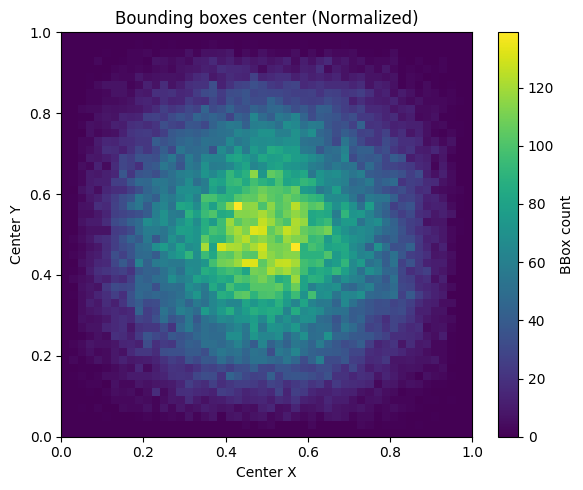

In [75]:
plot_center_heatmap(IMAGE_MAP_K)

<Figure size 640x480 with 0 Axes>

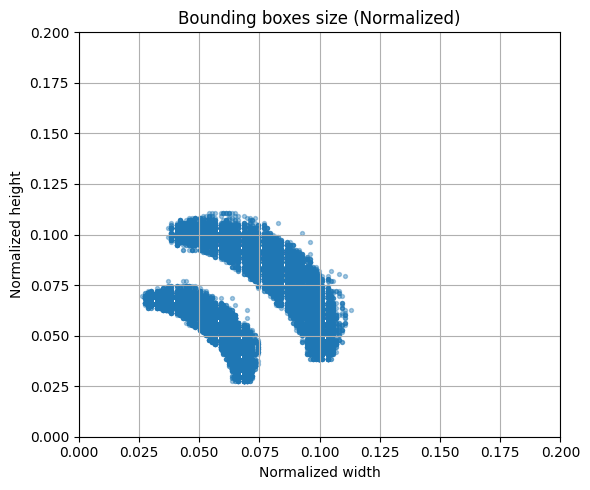

<Figure size 640x480 with 0 Axes>

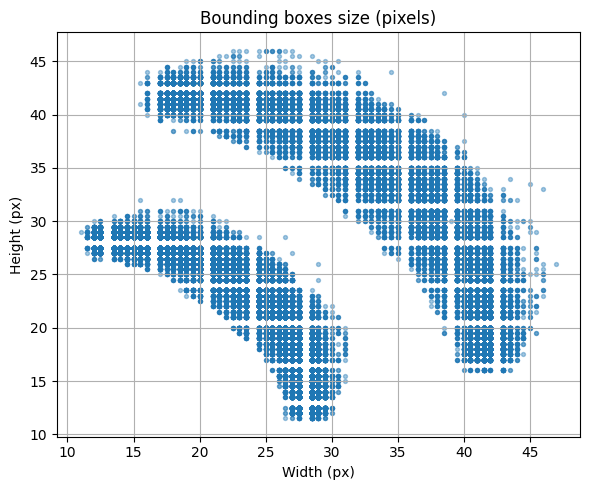

In [76]:
# Plotting of size in (x,y) plane

# In normalized units [0,1] x [0,1]
plot_size_normalized(IMAGE_MAP_K)

# In pixel units
plot_size_pixels(IMAGE_MAP_K)

#### K.6 Same-card recognition (SCR) metric analysis 

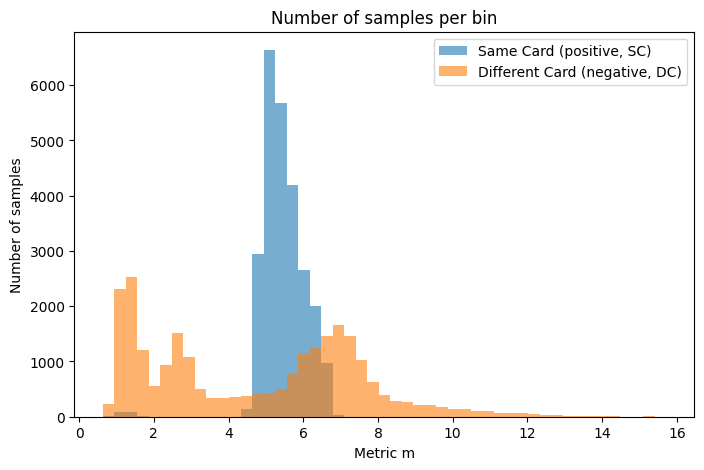

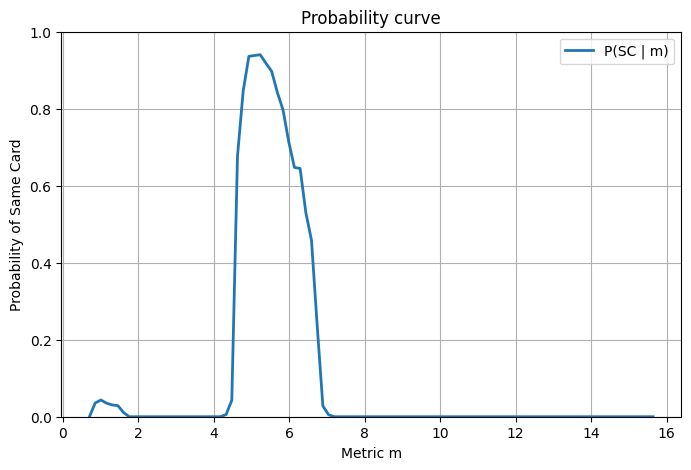

Match interval
conf=0.50 : 4.63 - 6.59
conf=0.55 : 4.63 - 6.44
conf=0.60 : 4.63 - 6.44
conf=0.65 : 4.63 - 6.14
conf=0.70 : 4.78 - 6.14
conf=0.75 : 4.78 - 5.99
conf=0.80 : 4.78 - 5.83
conf=0.85 : 4.93 - 5.68
conf=0.90 : 4.93 - 5.53
conf=0.95 : NOT FOUND


In [91]:
evaluate_metric(IMAGE_MAP_K)

#### K.7 Random samples (annotated)

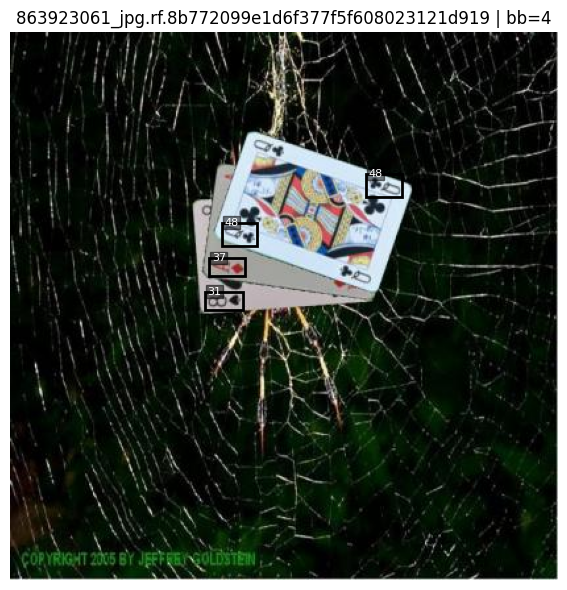

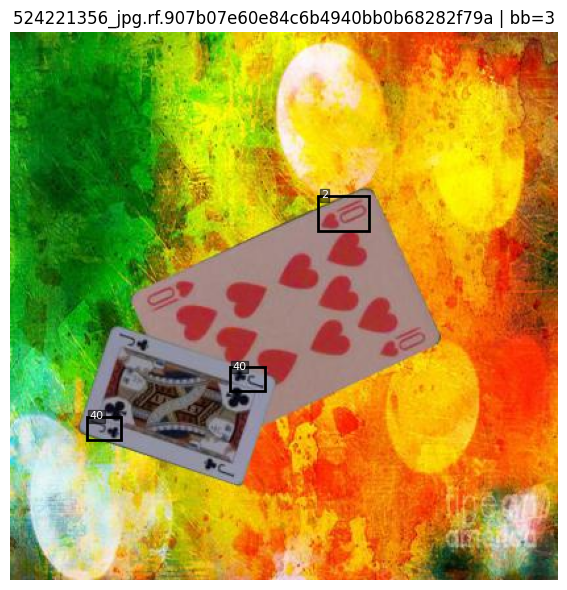

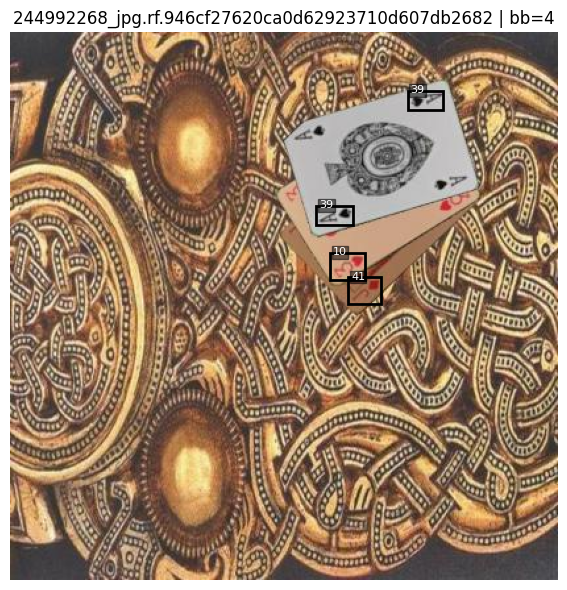

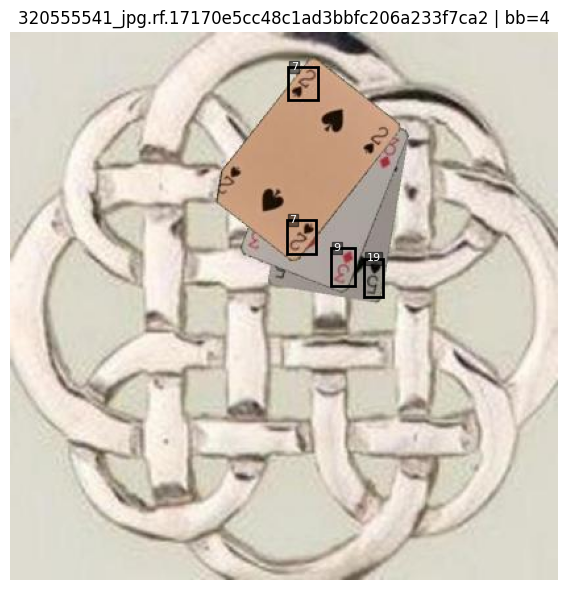

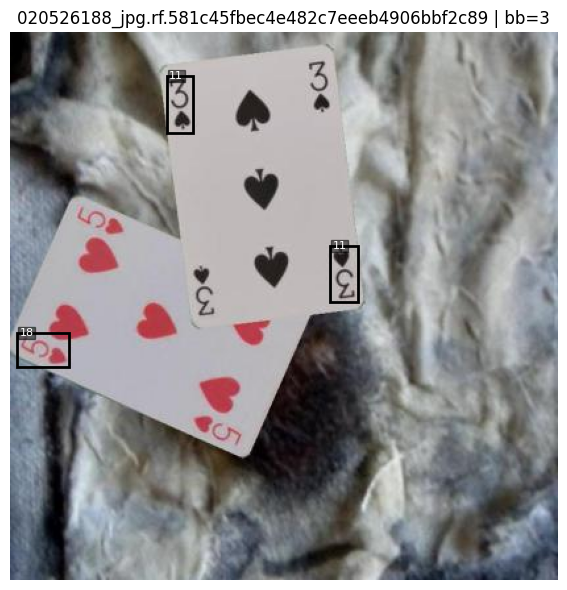

In [79]:
plot_random_samples(DATASET, IMAGE_MAP_K)

### Roboflow Dataset

In [80]:
DATASET = DATASETS[1]

In [81]:
IMAGE_MAP_R = construct_image_map(DATASET)
print("Image map constructed")

CATEGORY_MAP = construct_category_map(DATASET, IMAGE_MAP_R)
print("Category map constructed")

Image map constructed
Category map constructed


#### R.1 Dataset structure

In [82]:
print_tree(DATASET)

└── pcd_src_robo_plain/
    ├── *.txt [2]
    ├── *.yaml [1]
    ├── test/
    │   ├── images/
    │   │   ├── *.jpg [1010]
    │   └── labels/
    │       ├── *.txt [1010]
    ├── train/
    │   ├── images/
    │   │   ├── *.jpg [7070]
    │   └── labels/
    │       ├── *.txt [7070]
    └── valid/
        ├── images/
        │   ├── *.jpg [2020]
        └── labels/
            ├── *.txt [2020]


#### R.2 General information
- Number of images
- Number of categories
- Number of bounding boxes

In [83]:
print_general_info(IMAGE_MAP_R, CATEGORY_MAP)


--- GENERAL DATASET INFO ---
Total images: 10100
   Images with at least 1 bbox: 10100
Total categories: 52
Total bounding boxes: 40400


#### R.3 Image statistics

General images statistics:
- Mean (+ stddev) number of bounding boxes per image
- Min and Max number of bounding boxes per image
- Mean (+ stddev) categories present per image
- Min and Max categories present per image

Top images:
- Images with most bounding boxes
- Images with least bounding boxes
- Images with most distinct categories
- Images with least distinct categories

In [84]:
print_images_stats(IMAGE_MAP_R)


--- IMAGE STATISTICS ---
Mean bboxes per image: 4.00 (stddev: 0.00)
Min/Max bboxes per image: 4 / 4
Mean categories per image: 2.95 (stddev: 0.23)
Min/Max categories per image: 1 / 3

--- TOP IMAGES BY BBOX COUNT ---
> 491024110_jpg.rf.d507bfa7eca707c35b10d891c669c998: 4
> 171849661_jpg.rf.b08f4feff0a8de9e91d5bb293e0207cf: 4
> 126460529_jpg.rf.7701fb937fb31e59f659f25cafc2a6c7: 4
> 012942033_jpg.rf.7bea416f302d396a2abcca447636ae38: 4
> 654079340_jpg.rf.10cca912d7f07b357f484e7bba33956f: 4

--- BOTTOM IMAGES BY BBOX COUNT ---
> 429861043_jpg.rf.05034beaeed9068a168805273666147a: 4
> 809613329_jpg.rf.e96e806edbdd0f6f1cf2fa46d4ecd5de: 4
> 153254567_jpg.rf.6c75dc2f7d7773133182f8af40b93caa: 4
> 078141263_jpg.rf.6db3b59ae256f0b44e85d0b13dafe2b0: 4
> 000220022_jpg.rf.d00d41c98ed523360208468eb12c5d15: 4

--- TOP IMAGES BY CATEGORY COUNT ---
> 491024110_jpg.rf.d507bfa7eca707c35b10d891c669c998: 3
> 171849661_jpg.rf.b08f4feff0a8de9e91d5bb293e0207cf: 3
> 126460529_jpg.rf.7701fb937fb31e59f659f25cafc2

#### R.4 Category statistics

General categories statistics:
- Mean (+ stddev) number of bounding boxes per category
- Min and Max number of bounding boxes per category
- Mean (+ stddev) number of images where the category is found, per category
- Min and Max number of images where the category is found, per category

Top categories:
- Categories with most bounding boxes
- Categories with least bounding boxes
- Categories in most images
- Categories in least images

In [85]:
print_categories_stats(CATEGORY_MAP)


--- TOP CATEGORIES BY BBOX COUNT ---
>  5C (id=16): 854
>  QS (id=51): 831
>  QD (id=49): 830
>  4C (id=12): 821
>  3C (id= 8): 815

--- BOTTOM CATEGORIES BY BBOX COUNT ---
>  6H (id=22): 712
>  JH (id=42): 715
>  JD (id=41): 718
>  3D (id= 9): 730
>  9C (id=32): 730

--- TOP CATEGORIES BY IMAGE COUNT ---
>  5C (id=16): 617
>  7S (id=27): 604
>  QS (id=51): 603
>  KC (id=44): 603
>  4D (id=13): 600

--- BOTTOM CATEGORIES BY IMAGE COUNT ---
>  JH (id=42): 523
>  JD (id=41): 528
>  3D (id= 9): 537
>  8C (id=28): 542
>  7C (id=24): 543

--- CATEGORY STATISTICS ---
Mean bboxes per category: 776.92 (stddev: 31.67)
Min/Max bboxes per category: 712 / 854
Mean images per category: 572.10 (stddev: 21.30)
Min/Max images per category: 523 / 617
Imbalance ratio (bboxes): 1.20


#### R.5 Bounding boxes geometric plots

<Figure size 640x480 with 0 Axes>

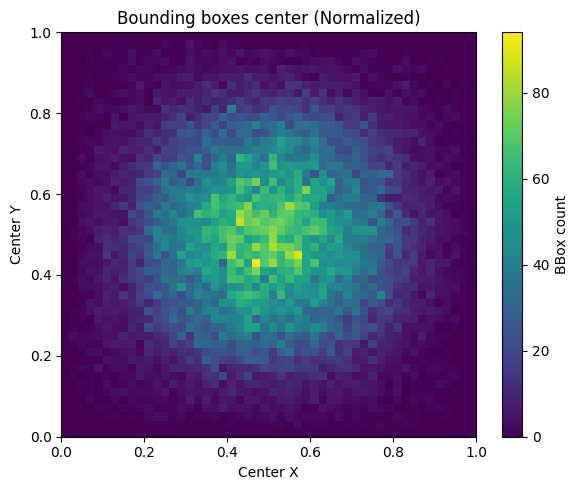

In [86]:
plot_center_heatmap(IMAGE_MAP_R)

<Figure size 640x480 with 0 Axes>

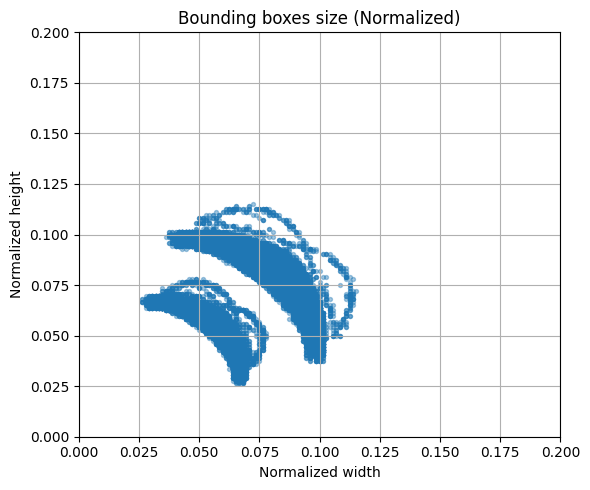

<Figure size 640x480 with 0 Axes>

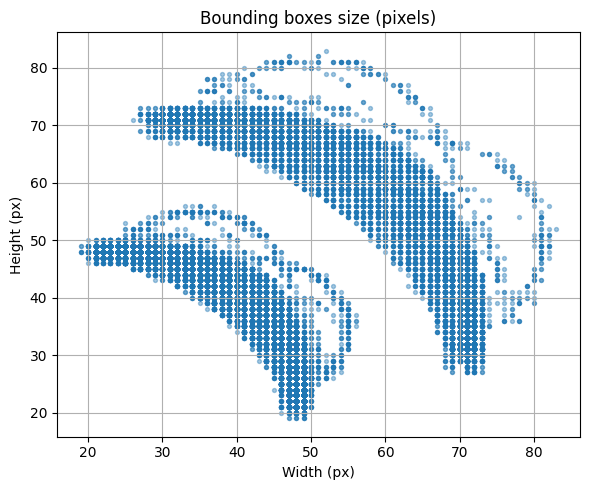

In [87]:
# Plotting of size in (x,y) plane

# In normalized units [0,1] x [0,1]
plot_size_normalized(IMAGE_MAP_R)

# In pixel units
plot_size_pixels(IMAGE_MAP_R)

#### R.6 Same-card recognition (SCR) metric analysis 

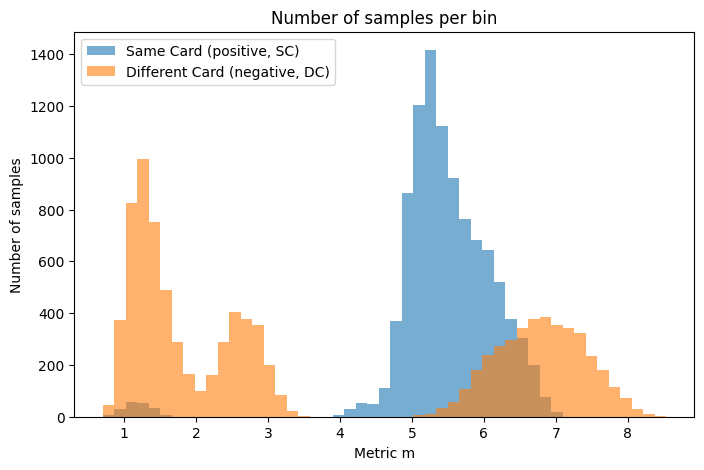

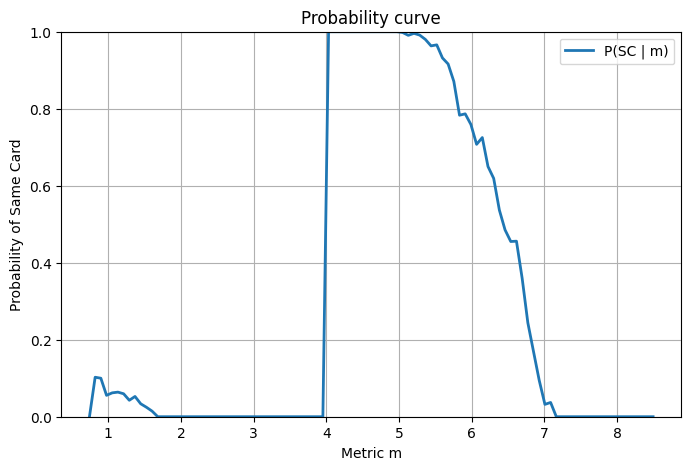

Match interval
conf=0.50 : 4.03 - 6.46
conf=0.55 : 4.03 - 6.38
conf=0.60 : 4.03 - 6.38
conf=0.65 : 4.03 - 6.22
conf=0.70 : 4.03 - 6.22
conf=0.75 : 4.03 - 6.07
conf=0.80 : 4.03 - 5.83
conf=0.85 : 4.03 - 5.83
conf=0.90 : 4.03 - 5.75
conf=0.95 : 4.03 - 5.60


In [88]:
evaluate_metric(IMAGE_MAP_R)

#### R.7 Random samples (annotated)

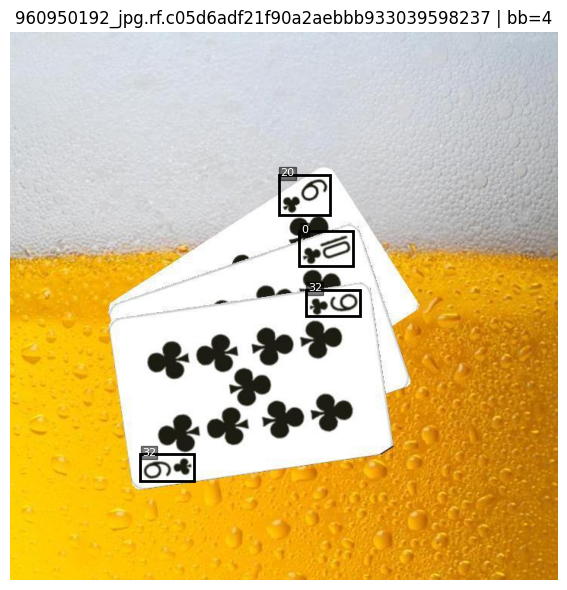

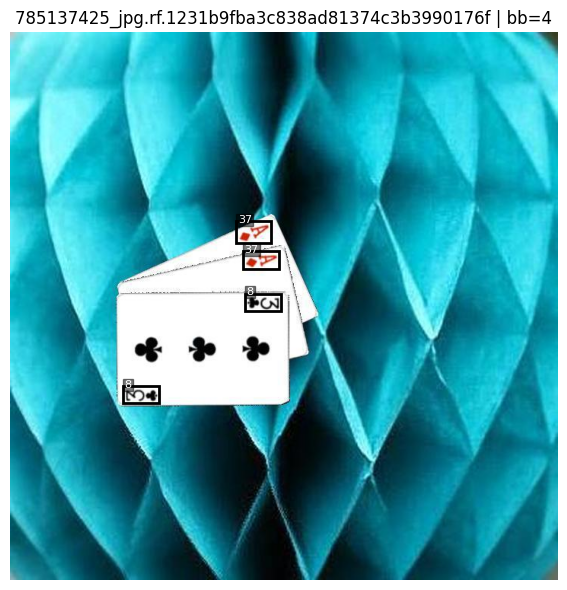

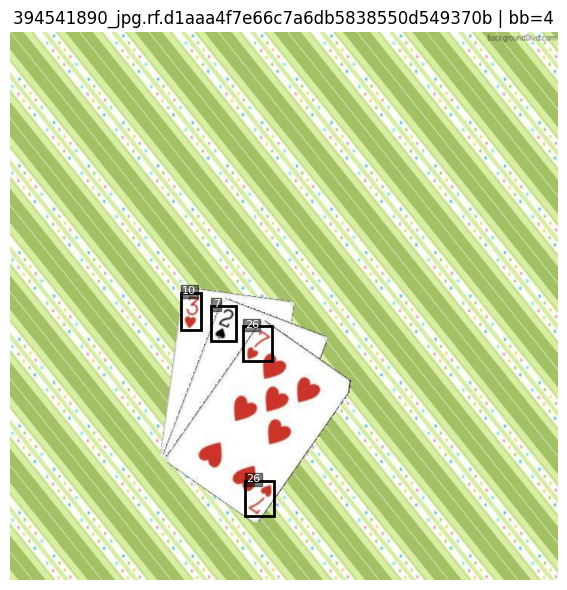

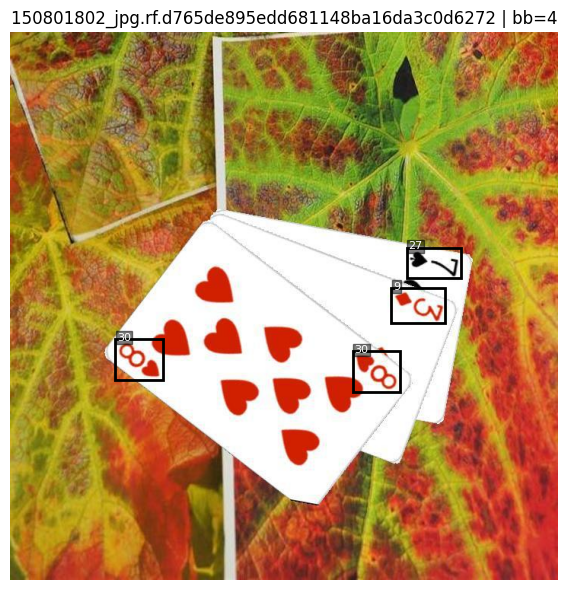

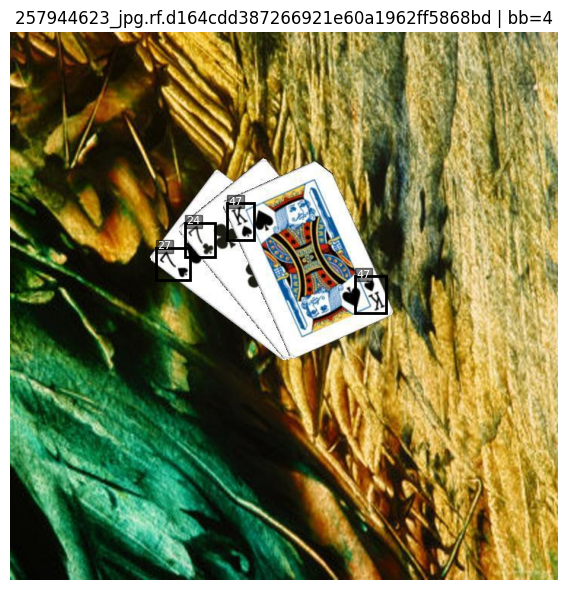

In [90]:
plot_random_samples(DATASET, IMAGE_MAP_R)